# 01. Background subtraction (baseline)

Heavy blur = "normal fabric" (two passes, the second without clearly abnormal pixels); anomaly = |tile − normal|. Catches spots and stains that differ from the local average. Baseline for every other method.

Method: `filters.py` (`METHOD_NAME = "background_subtraction"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/background_subtraction/`.

In [8]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "background_subtraction"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS   # enhancement before detection (chosen for fabric 02)
BG_SIGMA = 15             # blur strength for "normal fabric"
EXCLUDE = 14              # pass 2: pixels above this are left out of the "normal fabric" estimate


def method(tile):
    return F.background_subtraction(tile, STEPS, bg_sigma=BG_SIGMA, exclude=EXCLUDE)


fit = None

## Results for one fabric

In [9]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
score = strongest spot / the tile's own typical level (normalised);  threshold 4.70

                    predicted OK   predicted DAMAGED
good + hard neg.             628                  19
defect                         4                  34

false alarm rate    1.4% good_test, 3.4% hard negatives
recall              89.5%  (small <50 px: 82.6% of 23, large: 100.0% of 15)
strip level         false alarm 20.0% of 10 good strips, recall 89.5% of 38 defect strips
precision           64.2%
F1                  0.747
AUROC               0.984   (threshold-free ranking quality)
mean IoU            0.441 over all defect tiles, 0.458 over detected ones
time                30.0 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\background_subtraction


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

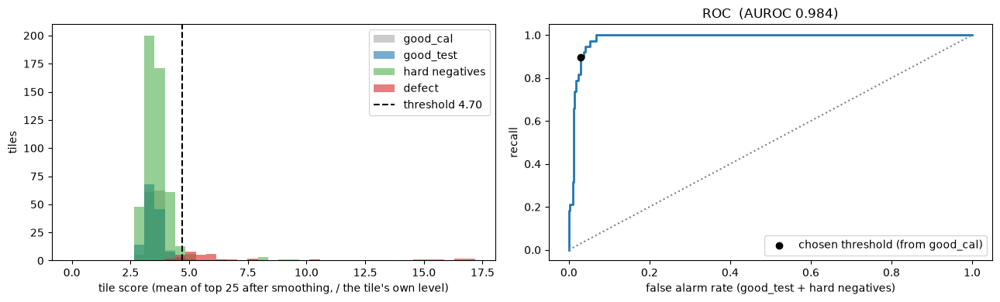

In [10]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [11]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      1     100%      0.13          151          5.12
006          7      7     100%      0.56         1260         16.42
019         23     20      87%      0.49           15          5.28
023          3      3     100%      0.01          778          5.88
030          4      3      75%      0.35           70          5.69


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

4 missed defects, 19 false alarms


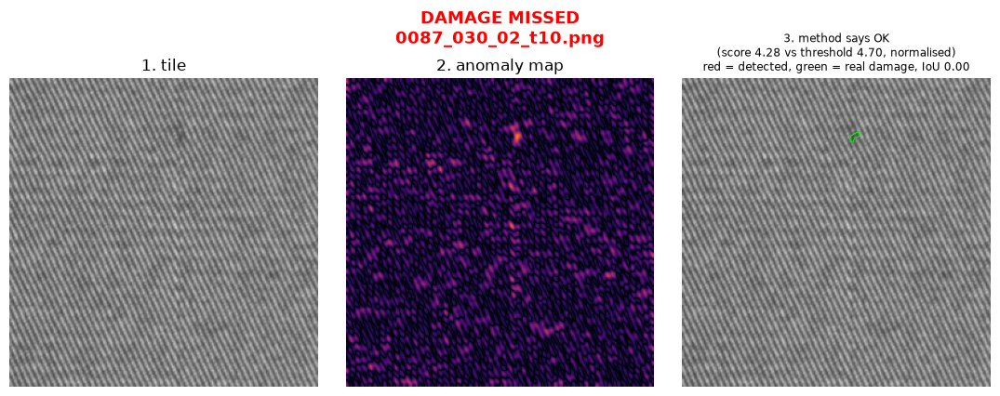

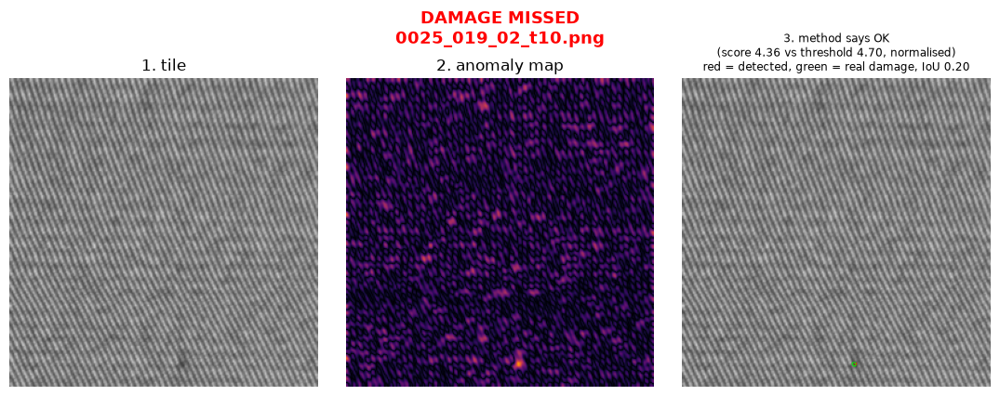

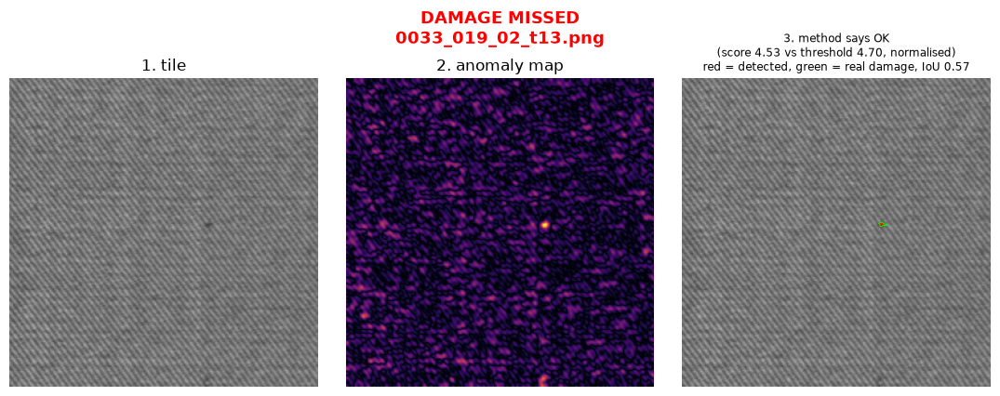

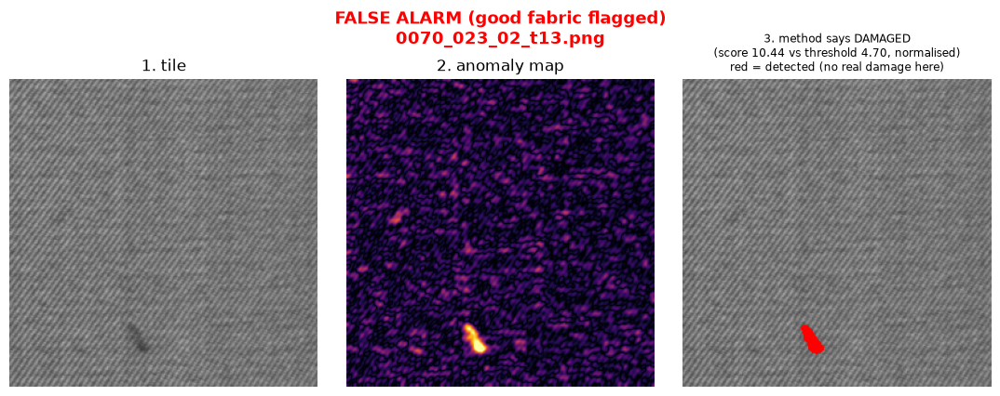

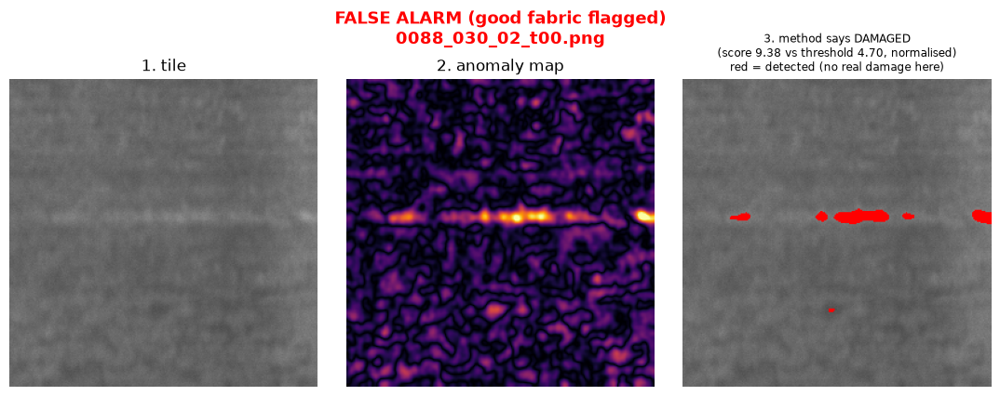

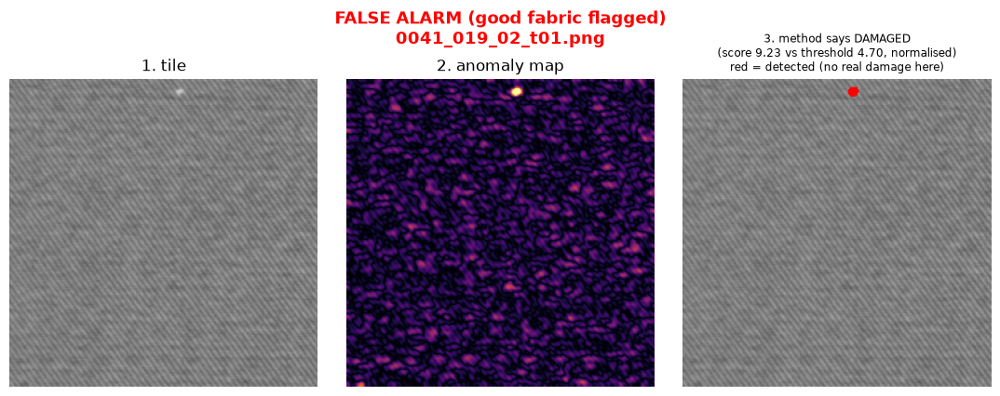

In [12]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


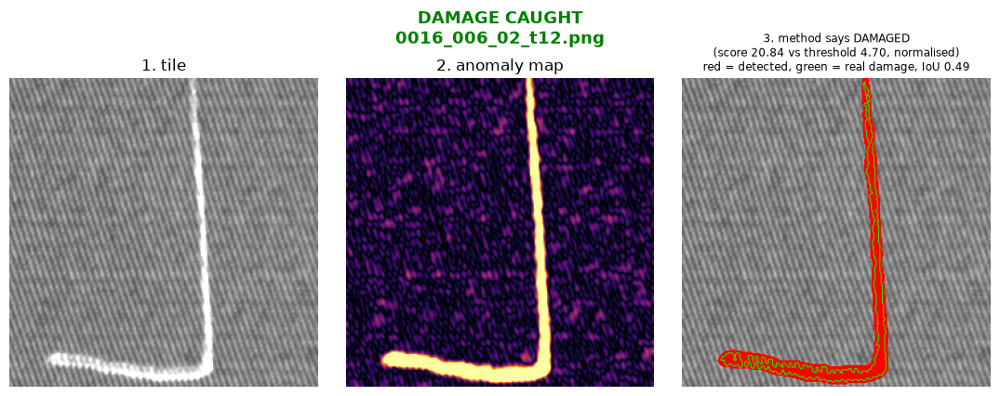

smallest defect: 0025_019_02_t10.png, 8 px


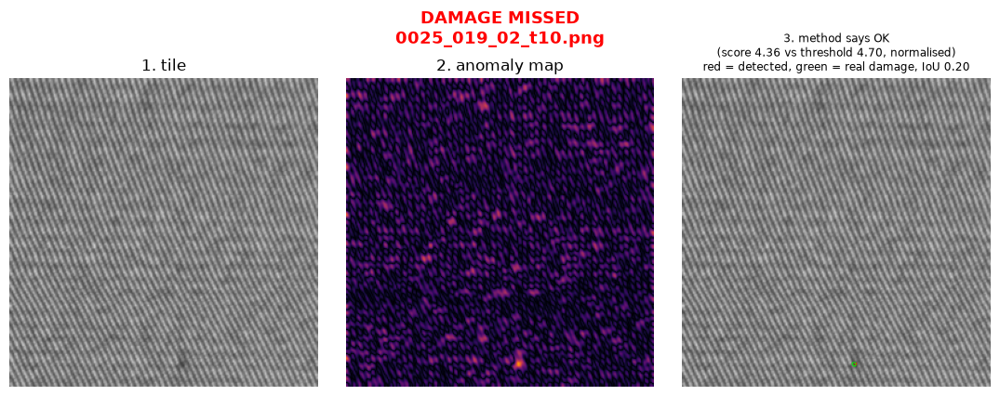

good tile: 0020_000_02_t15.png


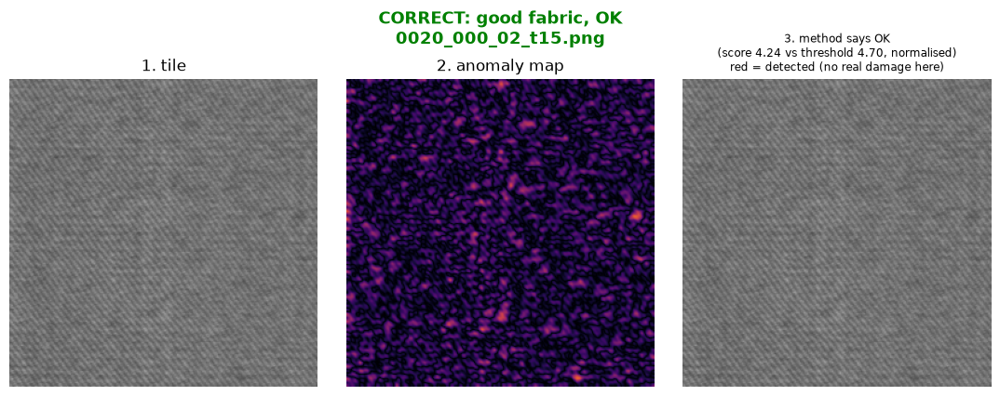

In [13]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

type   fabric  tiles  example tile           area px    score      thr  result
002        01     10  0005_002_01_t08.png       2514     5.92     4.43  DAMAGED (caught)
006        02      9  0016_006_02_t12.png       2111    20.84     4.70  DAMAGED (caught)
010        03     63  0103_010_03_t12.png      19060     2.28     2.88  OK (missed)
016        03      7  0021_016_03_t14.png        823     5.37     2.88  DAMAGED (caught)
019        02     40  0023_019_02_t08.png         54     5.13     4.70  DAMAGED (caught)
022        00     12  0065_022_00_t05.png        473     4.12     3.67  DAMAGED (caught)
023        01      6  0067_023_01_t09.png        577     5.35     4.43  DAMAGED (caught)
025        03      5  0107_025_03_t05.png         24     2.86     2.88  OK (missed)
027        05      1  0094_027_05_t01.png        265     6.08     5.05  DAMAGED (caught)
029        04      2  0083_029_04_t10.png        208    10.41     4.76  DAMAGED (caught)
030        03     14  0076_030_03_t09.png

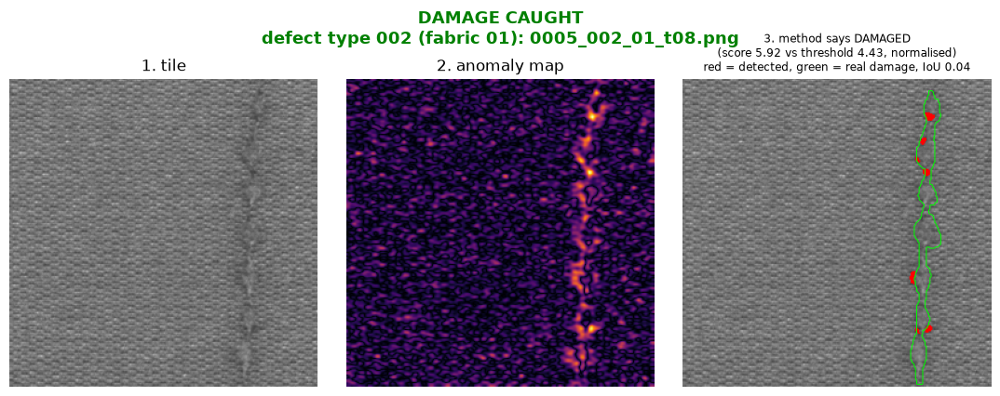

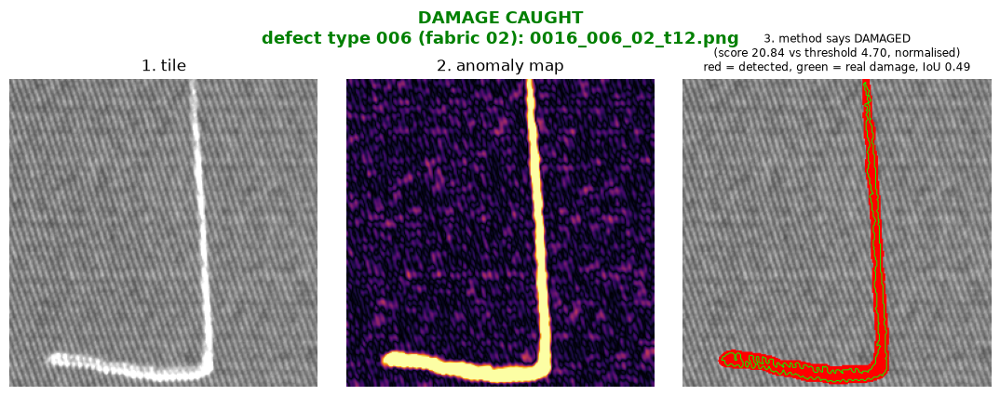

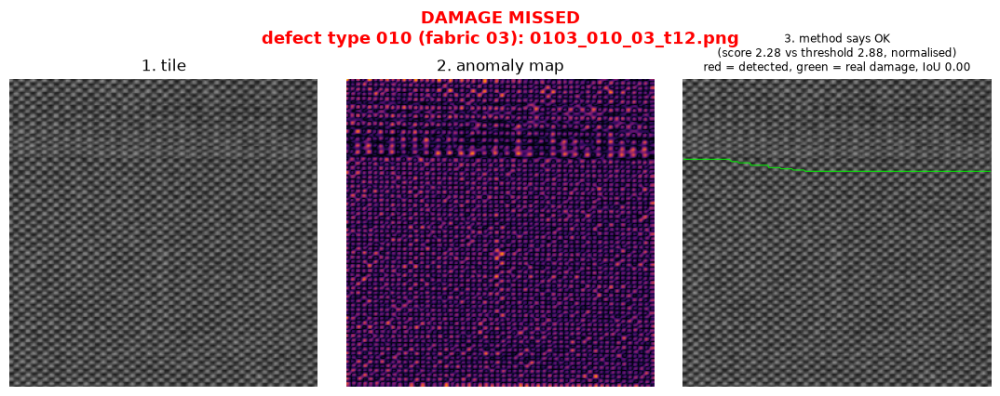

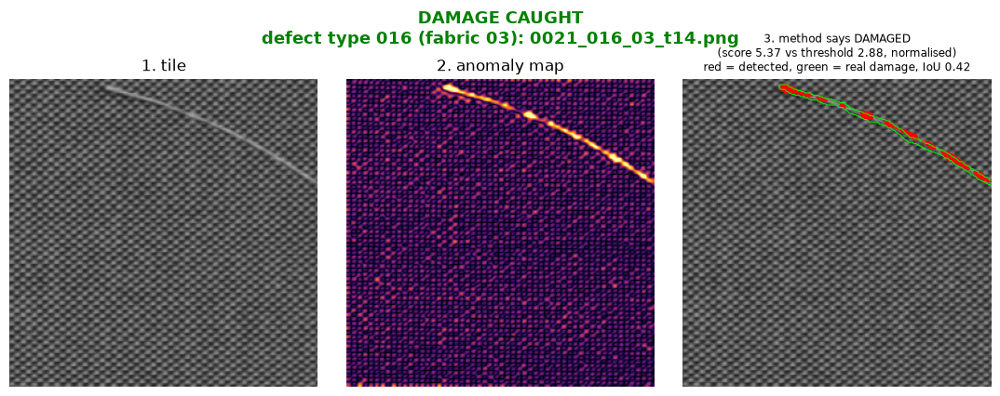

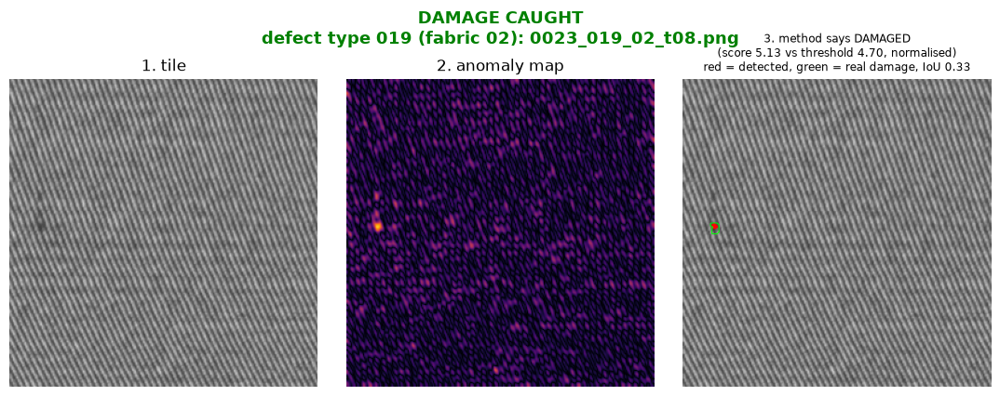

...

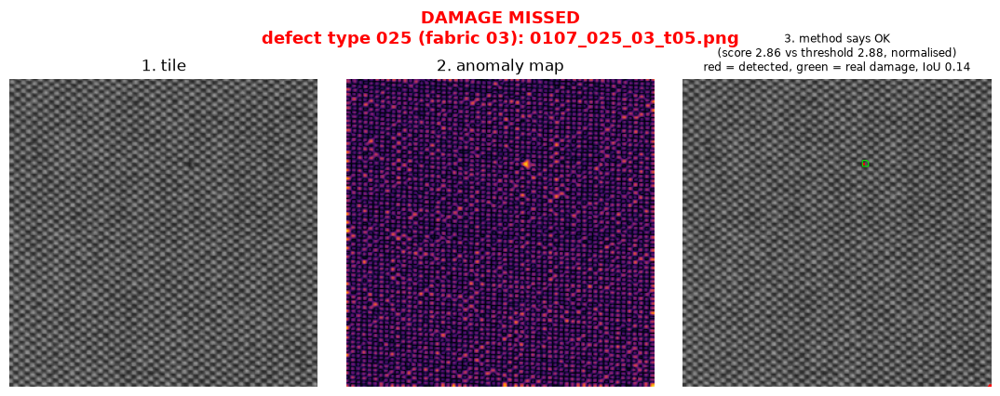

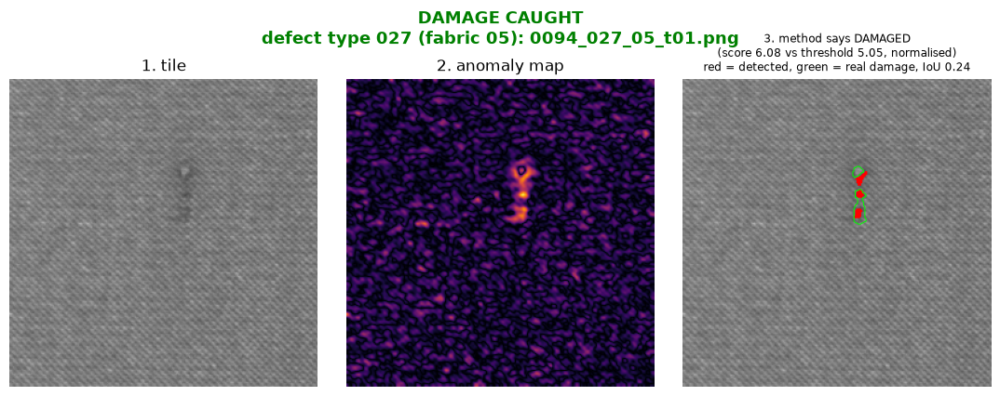

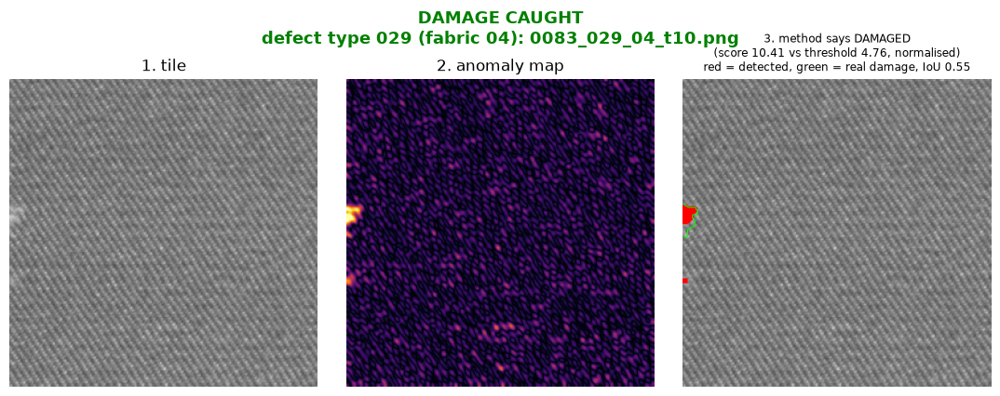

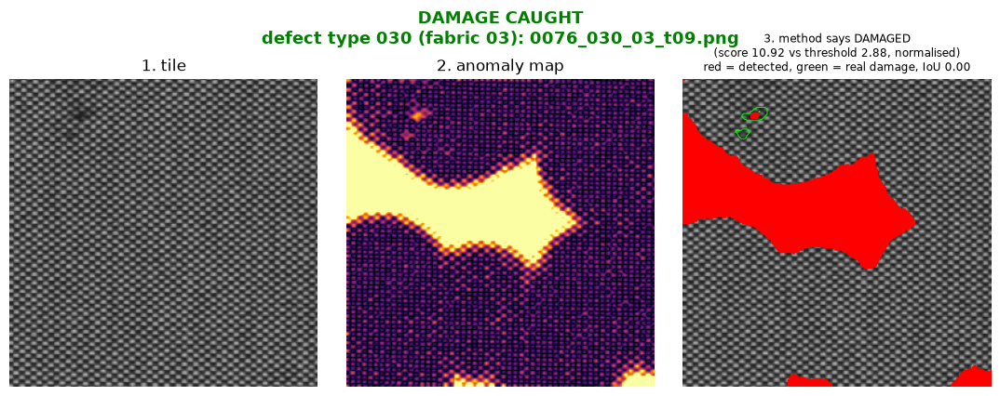

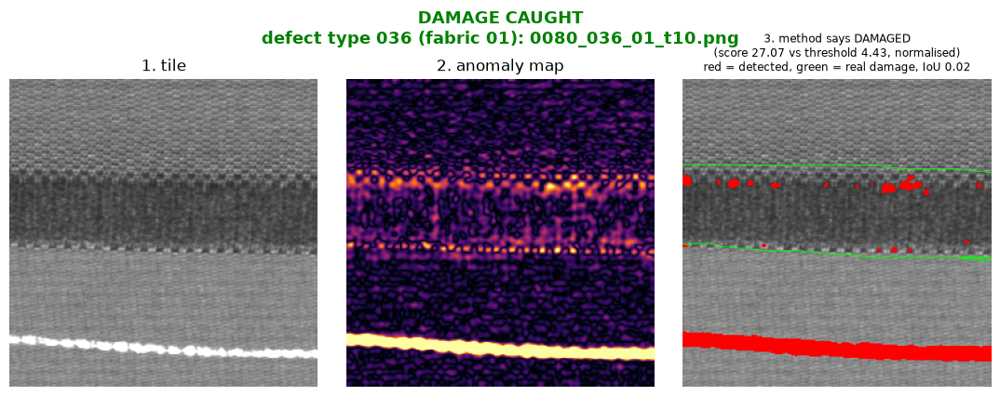

In [14]:
E.show_per_type(method, fit, res, **SETTINGS)

### Normal-fabric estimate
What the method treats as "normal fabric" for the largest defect tile (the defect is left out in pass 2).

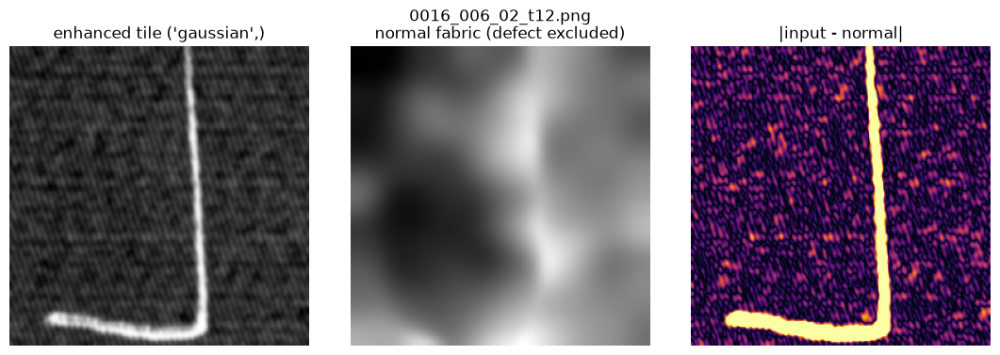

In [15]:
import matplotlib.pyplot as plt

_, p, _ = E.example_tiles(FABRIC)[0]
amap, t, normal = F.background_subtraction(E.load(p), STEPS, BG_SIGMA, EXCLUDE, return_normal=True)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
panels = [(t, "gray", f"enhanced tile {STEPS}"), (normal, "gray", "normal fabric (defect excluded)"),
          (F.display(amap, 2 * res["pix_thr"]), "inferno", "|input - normal|")]
for a, (img, cmap, title) in zip(ax, panels):
    a.imshow(img, cmap=cmap); a.set_title(title); a.axis("off")
fig.suptitle(p.name); plt.tight_layout(); plt.show()

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [16]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   1.8%   34.2%   77.8% 100.0%  75.0%    10.0%    85.7%  0.922  0.18   6.0
01        154   146     28   0.6%    8.2%   92.9%  50.0%  96.2%     9.1%    91.7%  0.981  0.14   6.1
02        140   507     38   1.4%    3.4%   89.5%  82.6% 100.0%    20.0%    89.5%  0.984  0.44   6.3
03        110   256     89   0.0%    5.9%   53.9%  69.2%  51.3%     0.0%    83.3%  0.817  0.09   6.8
04        138   129     12   5.8%    9.3%   83.3% 100.0%  71.4%    80.0%    90.0%  0.941  0.42   5.7
05        150    13      1   4.7%    0.0%  100.0%    n/a 100.0%    60.0%   100.0%  0.988  0.24  30.9
06        143    81      7  14.0%   18.5%   71.4%  60.0% 100.0%   100.0%    83.3%  0.936  0.19   8.5
-------------------------------------------------------------------------------------------